<a href="https://colab.research.google.com/github/ScrubOverlord/Emmanuel_INFO4670_Fall2026/blob/main/Emmanuel_Igwe_INFO4670_Week3_Assignment1_Template.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 1 — Making Sense of Northgate through Visualization
**INFO 4670 · Data Analysis and Knowledge Discovery**  ·  **Due: Sunday, 11:59 PM**

**Name:** Emmanuel Igwe    **Date:** 9/4/2026

**The situation.** The Provost's question stands: *which students are struggling, and can we see it earlier?* This week you answer it the way analysts do — not by reading rows, but by drawing the data. Every chart below is built by **adapting code from the Guided notebook**; the intellectual work is choosing the right chart and reading it honestly.

**For every chart you make, you must:**
1. **Choose** the chart type that fits the variable(s) and the question.
2. **Build** it in Colab from the Northgate files.
3. **Label** it fully — title, axis labels, and units/legend. *An unlabeled chart is an unfinished chart.*
4. **Write a STAR story** underneath it — Scope · Track · Articulate · Respond (defined on the Concepts deck).

**How to work:** run Setup and Load first. Then, for each question, copy the closest cell from the Guided notebook into the empty cell, adapt it, and fill in the STAR cell below it.

**Submit:** push this notebook to GitHub and submit the **GitHub link** in Canvas. (See the setup doc: *Colab_GitHub_Setup_INFO4670_Fall2026*.)

## Setup — run this first (you don't need to change it)

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Northgate house style (optional, but keeps your charts consistent)
NAVY = "#22303A"
RUST = "#C0562F"
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"]   = (8, 5)
plt.rcParams["axes.titlesize"]   = 13
plt.rcParams["axes.titleweight"] = "bold"

## Load the data — run this, then look before you plot

In [22]:
# STEP 1 — get the data into this notebook. Pick ONE option, then run.

DATA_DIR = "."   # OPTION 2 (default) · drag the 3 CSVs into the file panel on the left

# OPTION 1 · read from Google Drive — uncomment and edit the path:
# from google.colab import drive
# drive.mount("/content/drive")
# DATA_DIR = "/content/drive/MyDrive/.../Data"

import os
students = pd.read_csv(os.path.join(DATA_DIR, "student_records.csv"))
weekly   = pd.read_csv(os.path.join(DATA_DIR, "weekly_activity.csv"))
course   = pd.read_csv(os.path.join(DATA_DIR, "course_enrollments.csv"))
students.head()

,student_id,major,age,housing,commute_miles,work_hours_per_week,advisor_meetings,credits_attempted,final_gpa,study_hours_reported,enrollment_date,dropped_out
0,NU-101508,Data Science,27,Off-Campus,7.6,15,1,81,1.86,NaN,2023-09-13,1
1,NU-102438,Learning Technologies,25,With Family,14.3,35,1,100,2.06,9.5,2023-10-19,0
2,NU-102385,Learning Technologies,26,With Family,3.4,18,9,77,3.41,19.1,11/16/2022,0
3,NU-100767,Cyber Security,22,On-Campus,23.7,40,1,65,1.73,8.1,2024-05-03,0
4,NU-106054,Information Technology,21,Off-Campus,2.3,20,4,59,2.37,6.6,10/24/2022,0


In [23]:
# how many rows, which columns, what types?
students.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2027 entries, 0 to 2026
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   student_id            2027 non-null   object 
 1   major                 2027 non-null   object 
 2   age                   2027 non-null   int64  
 3   housing               2027 non-null   object 
 4   commute_miles         2027 non-null   float64
 5   work_hours_per_week   2027 non-null   int64  
 6   advisor_meetings      2027 non-null   int64  
 7   credits_attempted     2027 non-null   int64  
 8   final_gpa             2027 non-null   float64
 9   study_hours_reported  1772 non-null   float64
 10  enrollment_date       2027 non-null   object 
 11  dropped_out           2027 non-null   int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 190.2+ KB


# Part A — Guided questions
Build **one chart per question**. Each maps to one chart family from this week. Copy the closest Guided-notebook cell, adapt it, label it, then write its STAR story.

### Q1 · One quantitative variable
**How many hours per week do Northgate students work?** Describe what's typical, how spread out it is, and whether anyone stands apart.
→ *histogram* (add a *box plot* if it helps). Column: `work_hours_per_week` (from `students`).

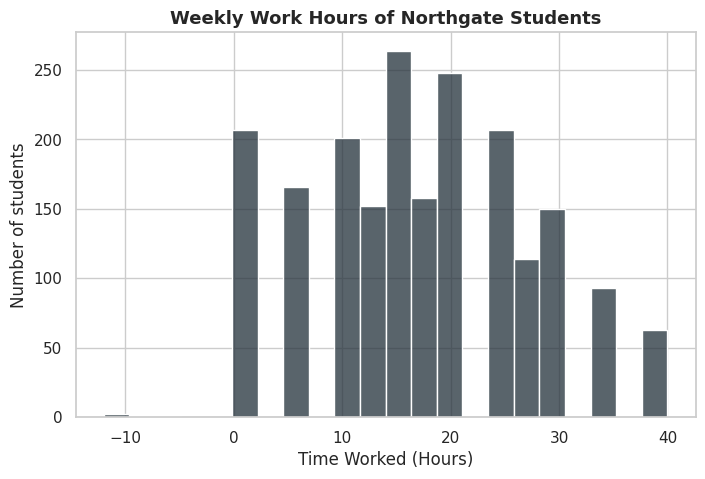

In [24]:

fig, ax = plt.subplots()
sns.histplot(data=students, x="work_hours_per_week", color=NAVY, ax=ax)
ax.set_title("Weekly Work Hours of Northgate Students")
ax.set_xlabel("Time Worked (Hours)")
ax.set_ylabel("Number of students")
plt.show()

**STAR story — Q1** *(write in your own words)*

- **Scope —** This chart shows the hour distribution of work_hours_per_week across [N] Northgate students.
- **Track —** how many hours per week do students typically work, and how much does that vary?
- **Articulate —** Though we see average work hours,around 15-20 hours per week, we do see a lot value spread with good amount working for 30 hours, 10 hours, and even 0 hours.
- **Respond —** We do notice a outlier with the -10 hours worked and flag it for as potiential false flag.

### Q2 · One categorical variable
**How does enrollment compare across majors?**
→ *sorted bar chart*. Column: `major` (from `students`).

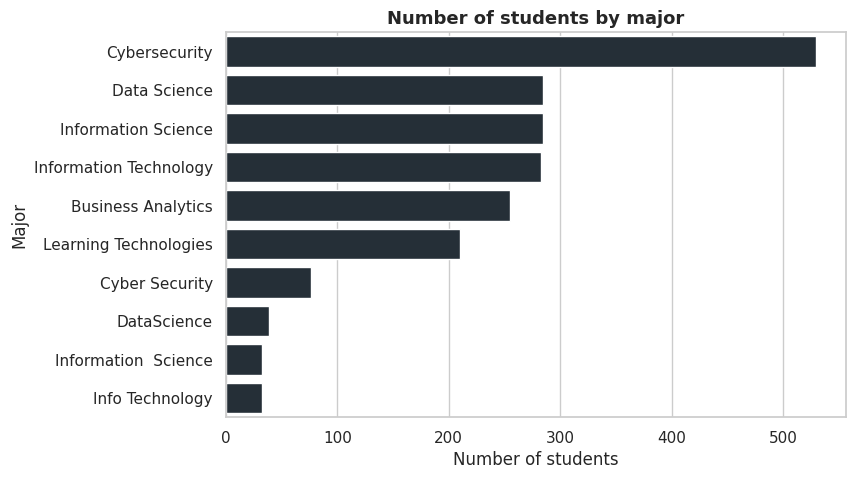

In [25]:
order = students["major"].value_counts().index
fig, ax = plt.subplots()
sns.countplot(data=students, y="major", order=order, color=NAVY, ax=ax)
ax.set_title("Number of students by major")
ax.set_xlabel("Number of students")
ax.set_ylabel("Major")
plt.show()



**STAR story — Q2** *(write in your own words)*

- **Scope —** what does this chart show? This chart shows the number of students enrolled in each major, based on the Northgate student course enrollment file. Majors appear on the y-axis and number of students appear on x-axis.
- **Track —** which question are you answering? We see which majors have the least and greatest enrollments, as well as the general distribution of the students per major.
- **Articulate —** what does the chart actually say? (typical value, spread, shape, comparison, or trend) We see unlike Q1, there isn't a large value spread but we have Cybersecurity with a large majority,2x the next tier. Has afour majors ;Data Science, Information Science, Information Technology, Business Analytics. They sit close together with roughly 270 students, with Learning Technologies just behind at around 210. Then there's a sharp plumit: four more bars sit far below the rest, in the 30ish range.
- **Respond —** anything odd or unexpected? what would you look at next? I noticed there are duplicate or similarly spellings of majors that already appear higher in the chart that could effect the true count on the majors.

### Q3 · A quantity, split by category
**Does final GPA differ across majors?** Read the exceptions, not just the boxes.
→ *box plot per major*. Columns: `final_gpa` and `major` (from `students`).

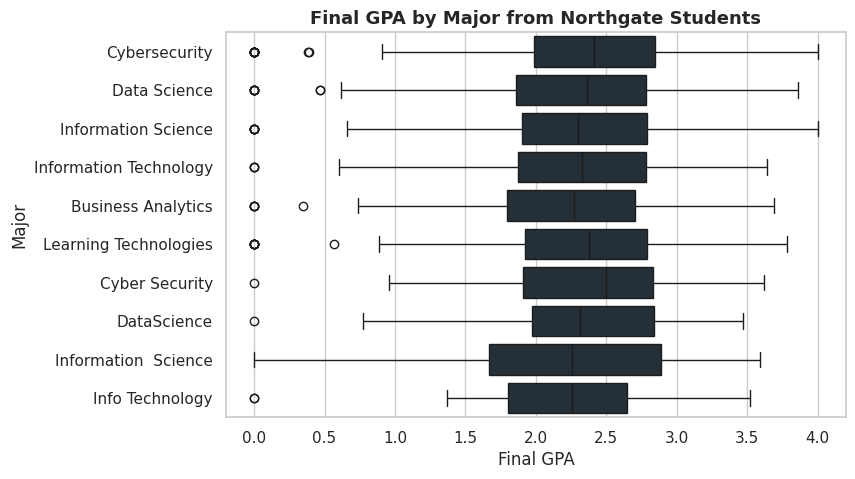

In [26]:
oorder = students["major"].value_counts().index
fig, ax = plt.subplots()
sns.boxplot(data=students, y="major", x="final_gpa", order=order, color=NAVY, ax=ax)
ax.set_title("Final GPA by Major from Northgate Students")
ax.set_xlabel("Final GPA")
ax.set_ylabel("Major")
plt.show()

**STAR story — Q3** *(write in your own words)*

- **Scope —** what does this chart show? This chart shows Final GPA by major, as box plots, for all students in the Northgate files. GPA on the y-axis and majors on the y-axis.
- **Track —** which question are you answering? Does final GPA differ by major, and how much does GPA vary within each major?"
- **Articulate —** what does the chart actually say? (typical value, spread, shape, comparison, or trend) The spread across the box plot is very large, witht the median sitting around 2.4 overall.
- **Respond —** anything odd or unexpected? what would you look at next? I notice some major have multiple outlier dots and check if they are a null defaulting to zero.

### Q4 · Two quantitative variables
**Is there a relationship between how far students commute and their final GPA?** Remember: *association is not causation.*
→ *scatterplot with a trend line*. Columns: `commute_miles` and `final_gpa` (from `students`).

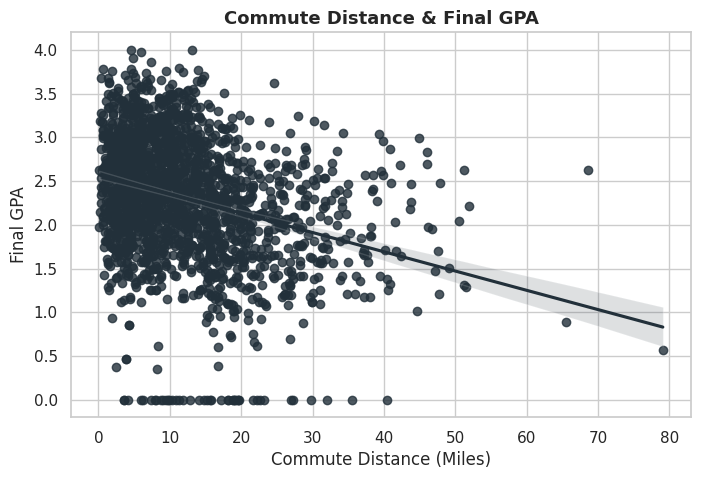

In [27]:
fig, ax = plt.subplots()
sns.regplot(data=students, x="commute_miles", y="final_gpa", color=NAVY, ax=ax)
ax.set_title("Commute Distance & Final GPA")
ax.set_xlabel("Commute Distance (Miles)")
ax.set_ylabel("Final GPA")
plt.show()


**STAR story — Q4** *(write in your own words)*

- **Scope —** what does this chart show? (which column(s), which students) This shows the commute distances for the difference student depending on the Final GPA.
- **Track —** which question are you answering? Is there a connetion between how far a student commutes and their final GPA scoring?"
- **Articulate —** what does the chart actually say? (typical value, spread, shape, comparison, or trend) There is a downward trend showing that a increase in commute distance has correlation with lower Final GPA scores,there is a dropping to roughly 1.0 or below for students commuting 70 to 80 miles. But there are alot of scatter and spread dot values so there a probablities that there are more factors to this situation.
- **Respond —** anything odd or unexpected? what would you look at next? Similar to previous question of the anomalous 0 GPA "students" and checking if the null values otherwise, I see nothing out of place.

### Q5 · Over time
**How does student engagement change across the semester?**
→ *line chart* of average weekly activity. Use the `weekly` table: `week` and `minutes_active` (you'll need to average by week first — see the Guided notebook).

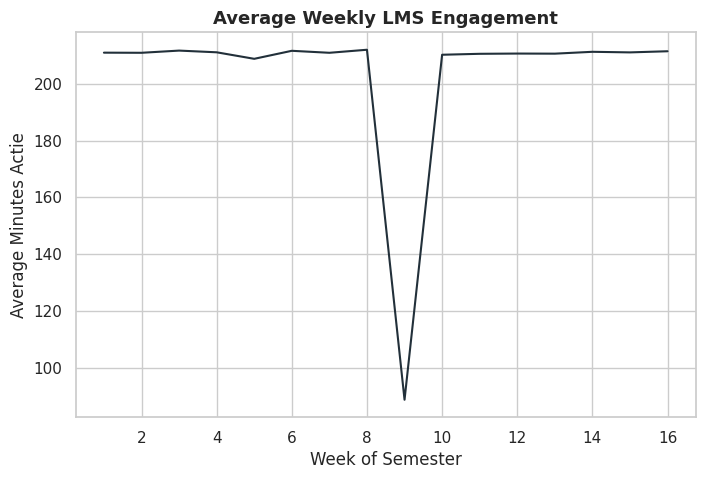

In [28]:
weekly_avg = weekly.groupby("week")["minutes_active"].mean().reset_index()

fig, ax = plt.subplots()
sns.lineplot(data=weekly_avg, x="week", y="minutes_active", color=NAVY, ax=ax)
ax.set_title("Average Weekly LMS Engagement")
ax.set_xlabel("Week of Semester")
ax.set_ylabel("Average Minutes Actie")
plt.show()


**STAR story — Q5** *(write in your own words)*

- **Scope —** what does this chart show?  This chart shows the average number of minutes students spent active in the LMS per week.
- **Track —** which question are you answering? How does student students active time spent with the LMS change over the course of a semester.
- **Articulate —** what does the chart actually say? (typical value, spread, shape, comparison, or trend) Engagement is consistent staying around 210 minutes per week from week 1 through week 8 before a suddent drop on week 9 to about 90 minutes then stablizes back to around 210 again til end of semester.
- **Respond —** anything odd or unexpected? what would you look at next? I look at the sudden fall on week 9 see if there were and problems like the LLM site being down or Holiday week break.

# Part B — Your own question (open)
Pose **one question of your own** about the Northgate students, choose the chart that answers it, build it, label it, and write its STAR story. Going beyond Part A is rewarded — a per-student line chart, a violin plot, or a chart of a messier column are all fair game.

**Your question:** \_\_\_\_\_\_\_\_



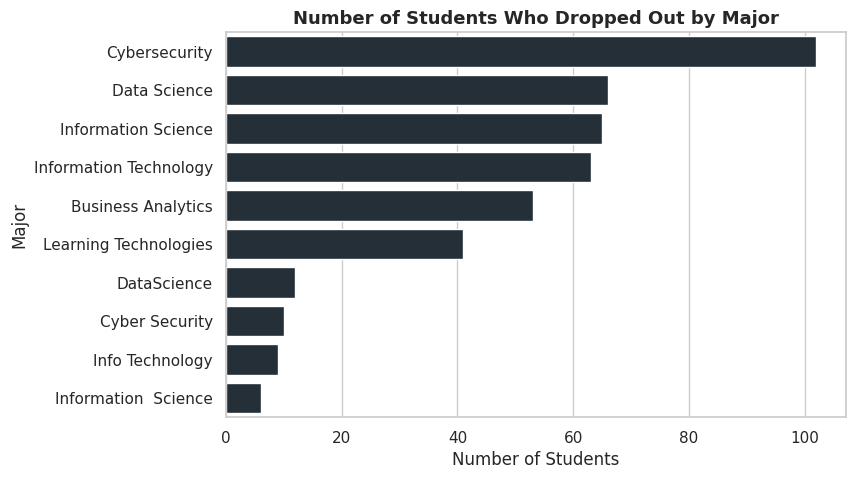

In [29]:
dropout_by_major = (students.groupby("major")["dropped_out"]
                     .sum()
                     .sort_values(ascending=False)
                     .reset_index())
dropout_by_major.columns = ["major", "dropout_count"]

fig, ax = plt.subplots()
sns.barplot(data=dropout_by_major, x="dropout_count", y="major", color=NAVY, ax=ax)
ax.set_title("Number of Students Who Dropped Out by Major")
ax.set_xlabel("Number of Students")
ax.set_ylabel("Major")
plt.show()

**STAR story — Part B** *(write in your own words)*

- **Scope —** what does this chart show? This chart show the total number of students who dropped out in each major.
- **Track —** which question are you answering? Which majors have lost the most students to dropout and could there be a correlation.
- **Articulate —** what does the chart actually say? Similar to Q2 Cybersecurity stands out with the most dropouts by a wide margin, having 102 students dropout.Data Science has 66, Information Science has 65, and Information Technology 63 form a middle cluster, followed by Business Analytics wih 53 and Learning Technologies has 41. This leaves Information Science as the least likely and safiest major to pickup.
- **Respond —** anything odd or unexpected? what would you look at next? I currently have no anomolies here, fun fact, if you at this by percentage Cybersecurity actually has one of the lower dropout ratio do to the amount of student who take it in the sample size given from Northgate students.

# Before you submit — checklist
- [ ] The notebook **runs top to bottom** with no errors (Runtime → Restart and run all).
- [ ] All **6 charts** are present, each with a title, labeled axes, and units/legend where needed.
- [ ] Each chart has a **complete STAR story**, including any exceptions you spotted.
- [ ] Part B question is written in and answered.
- [ ] Pushed to **GitHub**, and the **GitHub link** is submitted in Canvas.

**Rubric (70 pts):** chart choice 10 · correct build 20 · labeling 10 · STAR reading 18 · Part B question 4 · submission & professionalism 8.